In [2]:
import alpaca
print(alpaca.__version__)
import numpy as np
import matplotlib.pyplot as plt


plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': 'Computer Modern Roman',
    'text.usetex': True,
    'font.size': 9,
    'figure.figsize': (3.375, 2.8),
    'axes.labelsize': 9,
    'axes.titlesize': 10,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'lines.linewidth': 1.2,
    'text.latex.preamble': r'\usepackage{physics}'
})

1.2.0


In this notebook we obtain the decay widths of a heavy ALP ($m_a > 2 m_p$) into baryons, comparing them to some relevant mesonic decays and to the pQCD estimate of the inclusive hadronic width. The robustness of the results is checked by varying the coefficient $\widetilde{S}_B$ of the topological baryon operator, and by modifying the prescription to match into the pQCD-like behaviour.

In [3]:
ma = np.linspace(1.8, 3.0, 100)
fa = 1e3/(16*np.pi**2)
cG = alpaca.ALPcouplings({'cG': 1.0}, basis='VA_below', scale=5.0)

## $\tilde{S}_B = 0.025$

This is the baseline scenario, with $\widetilde{S}_B=0.025$ as extracted from the momentum-dependence of the topological form factor, and with a sharp transition between $\chi$ PT-like and pQCD-like scaling of the effective operators at $\mu_\star = 1.9\,\mathrm{GeV}$.

In [4]:
dw_pp = alpaca.decay_width('a -> p p ', ma, cG, fa, integrator='no_rge')
dw_nn = alpaca.decay_width('a -> n n ', ma, cG, fa, integrator='no_rge')

dw_SpSp = alpaca.decay_width('a -> Sigma+ Sigma+', ma, cG, fa, integrator='no_rge')
dw_S0S0 = alpaca.decay_width('a -> Sigma0 Sigma0', ma, cG, fa, integrator='no_rge')
dw_SmSm = alpaca.decay_width('a -> Sigma- Sigma-', ma, cG, fa, integrator='no_rge')

dw_Xi0Xi0 = alpaca.decay_width('a -> Xi0 Xi0', ma, cG, fa, integrator='no_rge')
dw_XimXim = alpaca.decay_width('a -> Xi- Xi-', ma, cG, fa, integrator='no_rge')

dw_LamLam = alpaca.decay_width('a -> Lambda Lambda', ma, cG, fa, integrator='no_rge')

In [5]:
dw_gg = alpaca.decay_width('a -> g g', ma, cG, fa, integrator='no_rge')

In [6]:
dw_omega = alpaca.decay_width('a -> omega omega', ma, cG, fa, integrator='no_rge')

In [7]:
dw_etappi0 = alpaca.decay_width("a -> eta' pi0 pi0", ma, cG, fa, integrator='no_rge')
dw_etappipm = alpaca.decay_width("a -> eta' pi+ pi-", ma, cG, fa, integrator='no_rge')

dw_etapi0 = alpaca.decay_width("a -> eta pi0 pi0", ma, cG, fa, integrator='no_rge')
dw_etapipm = alpaca.decay_width("a -> eta pi+ pi-", ma, cG, fa, integrator='no_rge')

dw_etappi = dw_etappi0 + dw_etappipm + dw_etapi0 + dw_etapipm

In [8]:
dw_NN = dw_pp + dw_nn
dw_sigma = dw_SpSp + dw_S0S0 + dw_SmSm
dw_xi = dw_Xi0Xi0 + dw_XimXim
dw_tot = dw_NN + dw_sigma + dw_xi + dw_LamLam

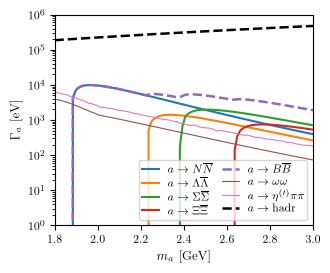

In [9]:
plt.semilogy(ma, dw_NN*1e9, lw=1.5, label=r'$a \to N \overline{N}$')
plt.semilogy(ma, dw_LamLam*1e9, lw=1.5, label=r'$a \to \Lambda \overline{\Lambda}$')
plt.semilogy(ma, dw_sigma*1e9, lw=1.5, label=r'$a \to \Sigma \overline{\Sigma}$')
plt.semilogy(ma, dw_xi*1e9, lw=1.5, label=r'$a \to \Xi \overline{\Xi}$')
plt.semilogy(ma, dw_tot*1e9, lw=1.8, label=r'$a \to B \overline{B}$', ls='--')

plt.semilogy(ma, dw_omega*1e9, lw=0.8, label=r'$a \to \omega \omega$')
plt.semilogy(ma, dw_etappi*1e9, lw=0.8, label=r"$a \to \eta^{(\prime)} \pi \pi$")
plt.semilogy(ma, dw_gg*1e9, lw=1.8, label=r'$a \to \mathrm{hadr}$', c='k', ls='--')

plt.xlim(1.8, 3.0)
plt.ylim(1, 1e6)
plt.legend(ncol=2, borderpad=0.3, labelspacing=0.2, handlelength=1.5, columnspacing=0.8)
plt.xlabel(r'$m_a$ [GeV]')
plt.ylabel(r'$\Gamma_a$ [eV]')

plt.tight_layout()
plt.savefig('decay_widths_baryons.pdf', dpi=300, bbox_inches='tight')

(0.0001, 1)

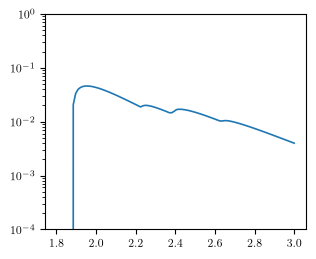

In [10]:
plt.semilogy(ma, dw_tot/dw_gg)
plt.ylim(1e-4, 1)

In [11]:
np.max(dw_tot/dw_gg)

np.float64(0.04581865617770641)

## $\tilde{S}_B \neq 0.025$

In [12]:
def dw_sbtilde(sbtilde):
    dw_pp_2 = alpaca.decay_width('a -> p p ', ma, cG, fa, integrator='no_rge', sbtilde = sbtilde)
    dw_nn_2 = alpaca.decay_width('a -> n n ', ma, cG, fa, integrator='no_rge', sbtilde = sbtilde)

    dw_SpSp_2 = alpaca.decay_width('a -> Sigma+ Sigma+', ma, cG, fa, integrator='no_rge', sbtilde = sbtilde)
    dw_S0S0_2 = alpaca.decay_width('a -> Sigma0 Sigma0', ma, cG, fa, integrator='no_rge', sbtilde = sbtilde)
    dw_SmSm_2 = alpaca.decay_width('a -> Sigma- Sigma-', ma, cG, fa, integrator='no_rge', sbtilde = sbtilde)

    dw_Xi0Xi0_2 = alpaca.decay_width('a -> Xi0 Xi0', ma, cG, fa, integrator='no_rge', sbtilde = sbtilde)
    dw_XimXim_2 = alpaca.decay_width('a -> Xi- Xi-', ma, cG, fa, integrator='no_rge', sbtilde = sbtilde)

    dw_LamLam_2 = alpaca.decay_width('a -> Lambda Lambda', ma, cG, fa, integrator='no_rge', sbtilde = sbtilde)

    dw_NN_2 = dw_pp_2 + dw_nn_2
    dw_sigma_2 = dw_SpSp_2 + dw_S0S0_2 + dw_SmSm_2
    dw_xi_2 = dw_Xi0Xi0_2 + dw_XimXim_2
    dw_tot_2 = dw_NN_2 + dw_sigma_2 + dw_xi_2 + dw_LamLam_2

    return dw_tot_2

In [13]:
dw_sbtilde_sup = [dw_sbtilde(sbtilde) for sbtilde in (0.025 + 0.031, 0.025 + 2*0.031)]
dw_sbtilde_inf = [dw_sbtilde(sbtilde) for sbtilde in (0.025 - 0.031, 0.025 - 2*0.031)]

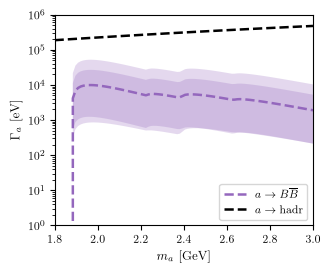

In [14]:
plt.semilogy(ma, dw_tot*1e9, lw=1.8, label=r'$a \to B \overline{B}$', ls='--', c='C4')
plt.semilogy(ma, dw_gg*1e9, lw=1.8, label=r'$a \to \mathrm{hadr}$', c='k', ls='--')
for i in range(2):
    plt.fill_between(ma, dw_sbtilde_inf[i]*1e9, dw_sbtilde_sup[i]*1e9,  alpha=0.25, linewidth=0, color='C4')

plt.xlim(1.8, 3.0)
plt.ylim(1, 1e6)
plt.legend(loc='lower right')
plt.xlabel(r'$m_a$ [GeV]')
plt.ylabel(r'$\Gamma_a$ [eV]')


plt.tight_layout()
plt.savefig('decay_widths_baryons_sbtilde.pdf', dpi=300, bbox_inches='tight')

In [15]:
np.max(dw_sbtilde_inf[0]/dw_gg), np.max(dw_sbtilde_sup[0]/dw_gg)

(np.float64(0.0057421172064791816), np.float64(0.12417417002262936))

In [16]:
np.max(dw_sbtilde_inf[1]/dw_gg), np.max(dw_sbtilde_sup[1]/dw_gg)

(np.float64(0.003920188656773906), np.float64(0.24080051842137437))

## $\mu_\star \neq 1.9\,\mathrm{GeV}$

In [17]:
def br_mupQCD(mu_pQCD, ma):
    dw_pp_2 = alpaca.decay_width('a -> p p ', ma, cG, fa, integrator='no_rge', mu_pQCD_baryons=mu_pQCD)
    dw_nn_2 = alpaca.decay_width('a -> n n ', ma, cG, fa, integrator='no_rge', mu_pQCD_baryons=mu_pQCD)

    dw_SpSp_2 = alpaca.decay_width('a -> Sigma+ Sigma+', ma, cG, fa, integrator='no_rge', mu_pQCD_baryons=mu_pQCD)
    dw_S0S0_2 = alpaca.decay_width('a -> Sigma0 Sigma0', ma, cG, fa, integrator='no_rge', mu_pQCD_baryons=mu_pQCD)
    dw_SmSm_2 = alpaca.decay_width('a -> Sigma- Sigma-', ma, cG, fa, integrator='no_rge', mu_pQCD_baryons=mu_pQCD)

    dw_Xi0Xi0_2 = alpaca.decay_width('a -> Xi0 Xi0', ma, cG, fa, integrator='no_rge', mu_pQCD_baryons=mu_pQCD)
    dw_XimXim_2 = alpaca.decay_width('a -> Xi- Xi-', ma, cG, fa, integrator='no_rge', mu_pQCD_baryons=mu_pQCD)

    dw_LamLam_2 = alpaca.decay_width('a -> Lambda Lambda', ma, cG, fa, integrator='no_rge', mu_pQCD_baryons=mu_pQCD)

    dw_NN_2 = dw_pp_2 + dw_nn_2
    dw_sigma_2 = dw_SpSp_2 + dw_S0S0_2 + dw_SmSm_2
    dw_xi_2 = dw_Xi0Xi0_2 + dw_XimXim_2
    dw_tot_2 = dw_NN_2 + dw_sigma_2 + dw_xi_2 + dw_LamLam_2

    return dw_tot_2/alpaca.decay_width('a -> g g', ma, cG, fa, integrator='no_rge')

In [18]:
mu_values = np.linspace(1.0, 3.0, 100)
ma_values = [2.0, 2.2, 2.4, 2.6, 2.8, 3.0]

br_results = []
for ma in ma_values:
    br_curve = np.array([br_mupQCD(mu, ma) for mu in mu_values])
    br_results.append(br_curve)
    print(ma)


2.0
2.2
2.4
2.6
2.8
3.0


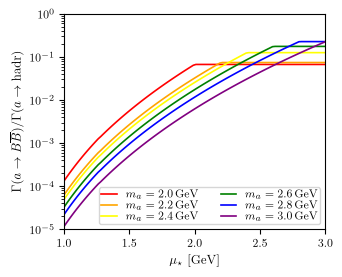

In [19]:
colors = ['red', 'orange', 'yellow', 'green', 'blue', 'purple']

for i, ma in enumerate(ma_values):
    plt.semilogy(mu_values, br_results[i], color=colors[i], label=fr'$m_a = {ma}\,\mathrm{{GeV}}$')
plt.xlabel(r'$\mu_\star$ [$\mathrm{GeV}$]')
plt.ylabel(r'$\Gamma(a\to B \overline{B}) / \Gamma(a\to \mathrm{hadr})$')
plt.xlim(1.0, 3.0)
plt.ylim(1e-5, 1)
plt.legend(loc='lower right', ncols=2, borderpad=0.2, labelspacing=0.1, handlelength=1.4)
plt.savefig('mus_dependence.pdf', bbox_inches='tight', dpi=300)

In [20]:
br_results[0][-1]/br_results[0][0]

np.float64(511.3356862170685)

In [21]:
br_results[5][-1]/br_results[5][0]

np.float64(19556.899990856822)

### Cubic spline interpolation

In [22]:
def br_mupQCD_spline(mu_pQCD, ma):
    dw_pp_2 = alpaca.decay_width('a -> p p ', ma, cG, fa, integrator='no_rge', mu_pQCD_baryons=mu_pQCD, formfactors_baryons_spline=True)
    dw_nn_2 = alpaca.decay_width('a -> n n ', ma, cG, fa, integrator='no_rge', mu_pQCD_baryons=mu_pQCD, formfactors_baryons_spline=True)

    dw_SpSp_2 = alpaca.decay_width('a -> Sigma+ Sigma+', ma, cG, fa, integrator='no_rge', mu_pQCD_baryons=mu_pQCD, formfactors_baryons_spline=True)
    dw_S0S0_2 = alpaca.decay_width('a -> Sigma0 Sigma0', ma, cG, fa, integrator='no_rge', mu_pQCD_baryons=mu_pQCD, formfactors_baryons_spline=True)
    dw_SmSm_2 = alpaca.decay_width('a -> Sigma- Sigma-', ma, cG, fa, integrator='no_rge', mu_pQCD_baryons=mu_pQCD, formfactors_baryons_spline=True)

    dw_Xi0Xi0_2 = alpaca.decay_width('a -> Xi0 Xi0', ma, cG, fa, integrator='no_rge', mu_pQCD_baryons=mu_pQCD, formfactors_baryons_spline=True)
    dw_XimXim_2 = alpaca.decay_width('a -> Xi- Xi-', ma, cG, fa, integrator='no_rge', mu_pQCD_baryons=mu_pQCD, formfactors_baryons_spline=True)

    dw_LamLam_2 = alpaca.decay_width('a -> Lambda Lambda', ma, cG, fa, integrator='no_rge', mu_pQCD_baryons=mu_pQCD, formfactors_baryons_spline=True)

    dw_NN_2 = dw_pp_2 + dw_nn_2
    dw_sigma_2 = dw_SpSp_2 + dw_S0S0_2 + dw_SmSm_2
    dw_xi_2 = dw_Xi0Xi0_2 + dw_XimXim_2
    dw_tot_2 = dw_NN_2 + dw_sigma_2 + dw_xi_2 + dw_LamLam_2

    return dw_tot_2/alpaca.decay_width('a -> g g', ma, cG, fa, integrator='no_rge')

In [23]:
br_results_spline = []
for ma in ma_values:
    br_curve = np.array([br_mupQCD_spline(mu, ma) for mu in mu_values])
    br_results_spline.append(br_curve)
    print(ma)

2.0
2.2
2.4
2.6
2.8
3.0


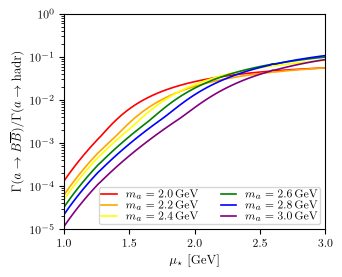

In [24]:
for i, ma in enumerate(ma_values):
    plt.semilogy(mu_values, br_results_spline[i], color=colors[i], label=fr'$m_a = {ma}\,\mathrm{{GeV}}$')
plt.xlabel(r'$\mu_\star$ [$\mathrm{GeV}$]')
plt.ylabel(r'$\Gamma(a\to B \overline{B}) / \Gamma(a\to \mathrm{hadr})$')
plt.xlim(1.0, 3.0)
plt.ylim(1e-5, 1)
plt.legend(loc='lower right', ncols=2, borderpad=0.2, labelspacing=0.1, handlelength=1.4)
plt.savefig('mus_dependence_spline.pdf', bbox_inches='tight', dpi=300)

In [25]:
br_results_spline[0][-1]/br_results_spline[0][0]

np.float64(425.50266988740145)

In [26]:
br_results_spline[0][-1]/br_results_spline[0][50]

np.float64(2.0551490683107585)

In [27]:
br_results_spline[5][-1]/br_results_spline[5][0]

np.float64(7528.892473604552)

In [28]:
br_results_spline[5][-1]/br_results_spline[5][50]

np.float64(12.364923052964055)